In [1]:
%pip install seaborn

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/viral_videos.csv")

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df["upload_day"] = pd.Categorical(
    df["upload_day"], categories = days, ordered = True
)

df["duration_group"] = pd.cut(
    df["duration_sec"],
    bins = [0, 300, 600, 900, 1200, np.inf],
    labels = ["0-5 min", "5-10 min", "10-15 min", "15-20 min", ">20 min"]
)



  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 16.1 MB/s  0:00:007.8 MB/s eta 0:00:01
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm

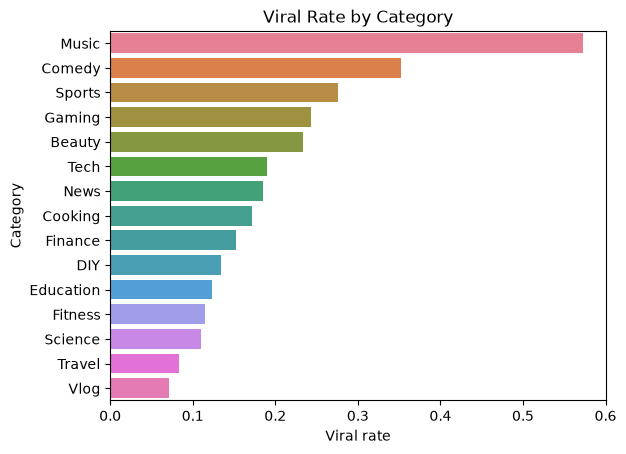

In [2]:
category_rate = (
    df.groupby("category", observed = True)["viral"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending = False)
)

sns.barplot(
    data = category_rate.reset_index(),
    x = "mean",
    y = "category",
    hue = "category",
    legend = False
)
plt.xlabel("Viral rate")
plt.ylabel("Category")
plt.title("Viral Rate by Category")
plt.show()
